In [2]:
from pathlib import Path
import sys
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_cleaning import clean_data
from utils.analytics import calculate_kpis, grouped_sum, monthly_trend

DATA_PATH = PROJECT_ROOT / "data" / "amazon_sales.xlsx"
raw_df = pd.read_excel(DATA_PATH)
print(f"Loaded: {DATA_PATH}")
print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())

Loaded: c:\Users\Rajnish\Downloads\Amazon-Sales-Analytics (2)\Amazon-Sales-Analytics\data\amazon_sales.xlsx
Shape: 10,000 rows × 13 columns


,Order_ID,Order_Date,Category,Product,Quantity,Unit_Price_INR,Discount_Pct,Total_Sales_INR,Profit_INR,Payment_Method,Fulfillment,Order_Status,Ship_State
0,IN-AMD-100000,2024-04-12,Apparel & Fashion,Saree with Unstitched Blouse,3,1129.14,0.25,2540.56,702.96,Cash on Delivery (COD),Seller Flex,Delivered,Telangana
1,IN-AMD-100001,2025-03-11,Apparel & Fashion,Men Denim Jeans,3,1159.01,0.05,3303.18,770.96,UPI,Amazon (FBA),Shipped,Kerala
2,IN-AMD-100002,2026-05-10,Beauty & Personal Care,Ubtan Face Wash,1,287.77,0.00,287.77,86.73,UPI,Amazon (FBA),Delivered,West Bengal
3,IN-AMD-100003,2024-09-27,Electronics & Mobiles,Wireless Earbuds,4,20928.14,0.05,79526.93,26466.63,Credit/Debit Card,Amazon (FBA),Shipped,Rajasthan
4,IN-AMD-100004,2024-04-16,Beauty & Personal Care,Sunscreen Gel SPF 50,1,931.65,0.15,791.90,217.90,UPI,Seller Flex,Delivered,Karnataka


In [3]:
display(pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=True)
}).sort_index())
display(raw_df.describe(include="all").T)

,dtype,missing_count,missing_pct,unique_values
Category,object,0,0.0,5
Discount_Pct,float64,0,0.0,6
Fulfillment,object,0,0.0,3
Order_Date,object,0,0.0,973
Order_ID,object,0,0.0,10000
Order_Status,object,0,0.0,4
Payment_Method,object,0,0.0,5
Product,object,0,0.0,25
Profit_INR,float64,0,0.0,8892
Quantity,int64,0,0.0,4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,10000,10000,IN-AMD-100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,10000,973,2025-12-26,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10000,5,Electronics & Mobiles,3045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product,10000,25,Laptop Backpack,652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,10000.0,NaN,NaN,NaN,2.4926,1.110076,1.0,2.0,2.0,3.0,4.0
Unit_Price_INR,10000.0,NaN,NaN,NaN,6821.399659,9183.501994,150.27,1002.8225,2290.08,7628.625,34992.8
Discount_Pct,10000.0,NaN,NaN,NaN,0.085575,0.076172,0.0,0.0,0.1,0.15,0.25
Total_Sales_INR,10000.0,NaN,NaN,NaN,15578.989389,24159.351687,118.82,1931.245,4795.8,17357.3325,139647.92
Profit_INR,10000.0,NaN,NaN,NaN,3316.700849,5805.8622,0.0,299.325,891.625,3250.53,45596.3
Payment_Method,10000,5,UPI,4972,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df, cleaning_report = clean_data(raw_df)
print("Cleaning report")
display(pd.Series(cleaning_report, name="value").to_frame())
print("\nCleaned shape:", df.shape)
display(df.head())

Cleaning report


,value
rows_before,10000
duplicate_rows_removed,0
missing_values_filled,{}
invalid_rows_removed,0
outlier_counts_iqr,"{'sales': 1250, 'profit': 1336, 'quantity': 0,..."
rows_after,10000



Cleaned shape: (10000, 13)


,order_id,order_date,category,product,quantity,unit_price,discount_pct,sales,profit,payment_method,fulfillment,order_status,ship_state
0,IN-AMD-100000,2024-04-12,Apparel & Fashion,Saree with Unstitched Blouse,3,1129.14,0.25,2540.56,702.96,Cash on Delivery (COD),Seller Flex,Delivered,Telangana
1,IN-AMD-100001,2025-03-11,Apparel & Fashion,Men Denim Jeans,3,1159.01,0.05,3303.18,770.96,UPI,Amazon (FBA),Shipped,Kerala
2,IN-AMD-100002,2026-05-10,Beauty & Personal Care,Ubtan Face Wash,1,287.77,0.00,287.77,86.73,UPI,Amazon (FBA),Delivered,West Bengal
3,IN-AMD-100003,2024-09-27,Electronics & Mobiles,Wireless Earbuds,4,20928.14,0.05,79526.93,26466.63,Credit/Debit Card,Amazon (FBA),Shipped,Rajasthan
4,IN-AMD-100004,2024-04-16,Beauty & Personal Care,Sunscreen Gel SPF 50,1,931.65,0.15,791.90,217.90,UPI,Seller Flex,Delivered,Karnataka


,category,rows,share_pct
0,Electronics & Mobiles,3045,30.45
1,Apparel & Fashion,2580,25.8
2,Home & Kitchen,1888,18.88
3,Beauty & Personal Care,1499,14.99
4,Pantry & Groceries,988,9.88


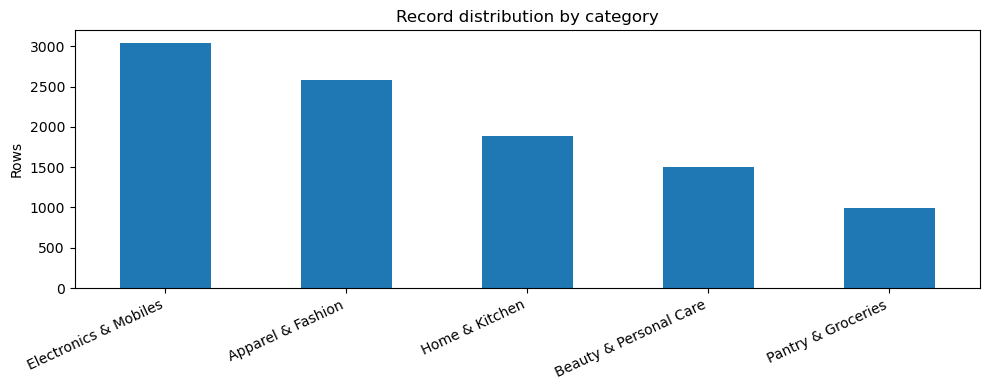

In [6]:
#Checking Data Imbalance 
if "category" in df.columns:
    category_counts = df["category"].value_counts(dropna=False).rename_axis("category").reset_index(name="rows")
    category_counts["share_pct"] = category_counts["rows"] / category_counts["rows"].sum() * 100
    display(category_counts)
    plt.figure(figsize=(10, 4))
    category_counts.set_index("category")["rows"].plot(kind="bar")
    plt.title("Record distribution by category")
    plt.xlabel("")
    plt.ylabel("Rows")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Category column unavailable; category-level analysis cannot be calculated.")

## 4. Core KPIs — overall sales and profitability

Definitions:
- **Total Sales:** sum of transaction sales values.
- **Total Profit:** sum of profit values.
- **Total Orders:** distinct order IDs when available; otherwise row count as a documented proxy.
- **Total Units Sold:** sum of quantity.
- **Average Order Value (AOV):** total sales divided by distinct orders.
- **Profit Margin:** total profit divided by total sales × 100.

Order count and AOV should be interpreted carefully if a future dataset contains multiple rows per order.

In [7]:
kpis = calculate_kpis(df)
kpi_table = pd.DataFrame([
    ("Total Sales", kpis["total_sales"], "INR"),
    ("Total Profit", kpis["total_profit"], "INR"),
    ("Total Orders", kpis["total_orders"], "orders"),
    ("Total Units Sold", kpis["units_sold"], "units"),
    ("Average Order Value", kpis["average_order_value"], "INR/order"),
    ("Profit Margin", kpis["profit_margin_pct"], "%")
], columns=["Metric", "Value", "Unit"])
display(kpi_table.style.format({"Value": lambda x: f"{x:,.2f}" if pd.notna(x) else "Not available"}))

,Metric,Value,Unit
0,Total Sales,"155,789,893.89",INR
1,Total Profit,"33,167,008.49",INR
2,Total Orders,"10,000.00",orders
3,Total Units Sold,"24,926.00",units
4,Average Order Value,"15,578.99",INR/order
5,Profit Margin,21.29,%


## 5. Monthly sales and profit trend

The month field is derived from `Order_Date`. If dates are missing or unparsable, those rows are excluded from the monthly trend only.

,month,sales,profit
20,2025-09,4645851.23,978708.78
21,2025-10,4786859.11,983414.48
22,2025-11,5110161.44,1197245.96
23,2025-12,4424179.17,983901.42
24,2026-01,4907181.04,1068832.87
25,2026-02,4324986.58,906184.52
26,2026-03,4854721.92,1074182.43
27,2026-04,5193546.45,1089945.17
28,2026-05,4795167.11,1057988.22
29,2026-06,5767141.03,1222177.09


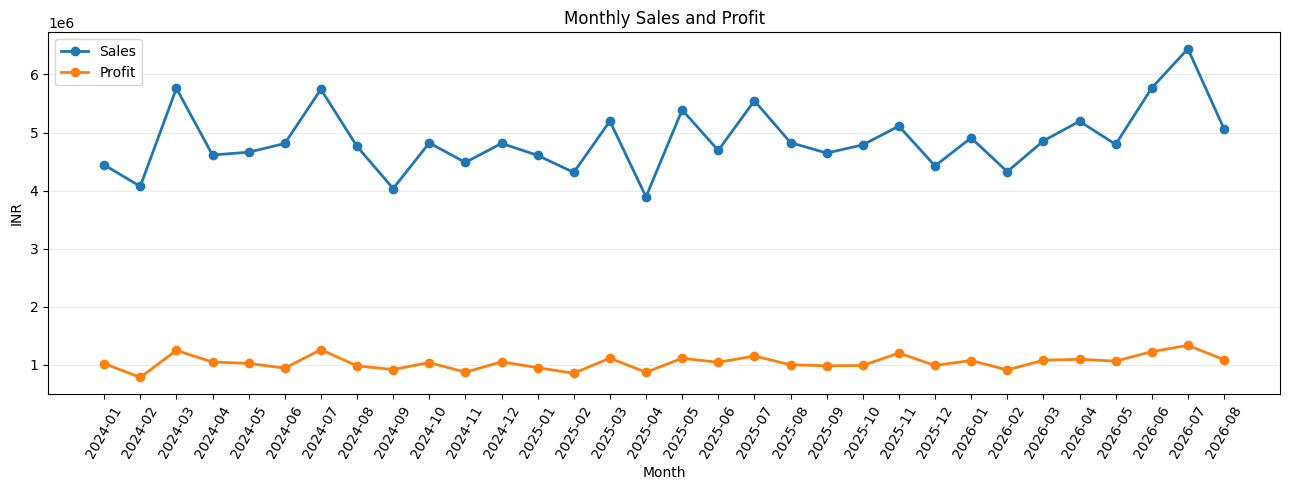

In [6]:
trend = pd.DataFrame(monthly_trend(df))
if not trend.empty:
    display(trend.tail(12))
    fig, ax = plt.subplots(figsize=(13, 5))
    if "sales" in trend:
        ax.plot(trend["month"], trend["sales"], marker="o", linewidth=2, label="Sales")
    if "profit" in trend:
        ax.plot(trend["month"], trend["profit"], marker="o", linewidth=2, label="Profit")
    ax.set_title("Monthly Sales and Profit")
    ax.set_ylabel("INR")
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=.25)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Monthly trend unavailable: date and/or metric columns are missing.")

## 6. Category performance — sales, profit, and units

These charts compare categories on three separate measures. High sales do not necessarily imply high profit, so the metrics are reviewed independently.

,total
category,
Electronics & Mobiles,1.235695e+08
Home & Kitchen,1.797322e+07
Apparel & Fashion,9.831025e+06
Beauty & Personal Care,2.889178e+06
Pantry & Groceries,1.526964e+06


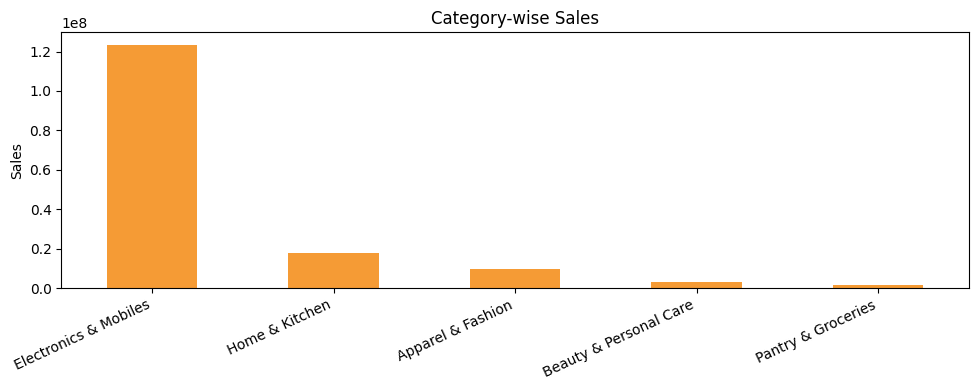

,total
category,
Electronics & Mobiles,26310257.24
Home & Kitchen,3837268.36
Apparel & Fashion,2085354.00
Beauty & Personal Care,604390.41
Pantry & Groceries,329738.48


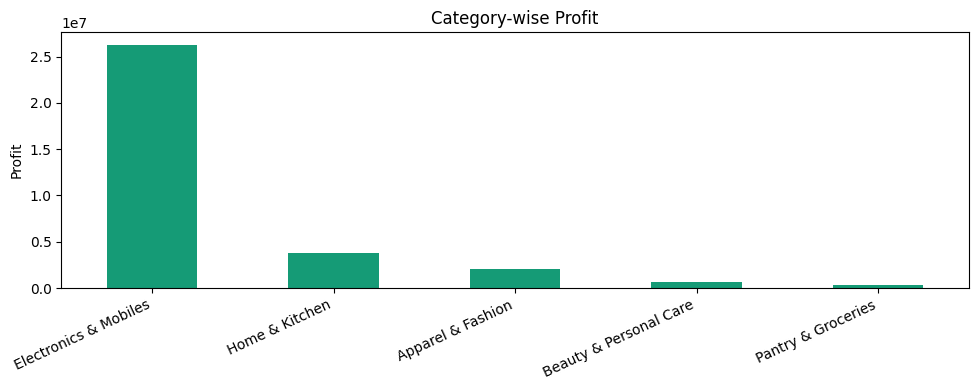

,total
category,
Electronics & Mobiles,7579
Apparel & Fashion,6452
Home & Kitchen,4684
Beauty & Personal Care,3734
Pantry & Groceries,2477


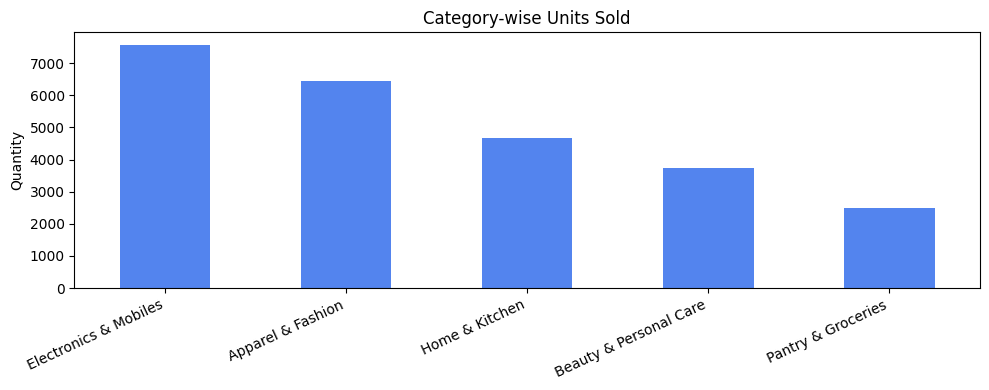

In [7]:
def plot_grouped_metric(df, group_col, value_col, title, color):
    if group_col not in df or value_col not in df:
        print(f"Cannot calculate {title}: required column missing.")
        return
    grouped = df.groupby(group_col, dropna=False)[value_col].sum().sort_values(ascending=False)
    display(grouped.rename("total").to_frame())
    plt.figure(figsize=(10, 4))
    grouped.plot(kind="bar", color=color)
    plt.title(title)
    plt.xlabel("")
    plt.ylabel(value_col.replace("_", " ").title())
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

plot_grouped_metric(df, "category", "sales", "Category-wise Sales", "#f59b35")
plot_grouped_metric(df, "category", "profit", "Category-wise Profit", "#159b76")
plot_grouped_metric(df, "category", "quantity", "Category-wise Units Sold", "#5384ee")

## 7. Top 10 products by sales revenue

Rank products by the sum of sales values. The table also includes profit and units sold where available, giving useful context beyond revenue rank.

,sales,profit,quantity
product,,,
Laptop Backpack,26529187.41,5628644.03,1641
Power Bank 20000mAh,25548449.07,5496680.51,1573
5G Smartphone,24330766.23,5109132.92,1478
Wireless Earbuds,23848640.89,5204191.90,1475
Smartwatch,23312463.47,4871607.88,1412
Stainless Steel Dinner Set,3865114.25,819333.80,953
Cotton Bedsheet Double,3789133.82,843105.06,998
Water Purifier,3785924.80,794225.82,992
Induction Cooktop,3510999.56,761204.61,907


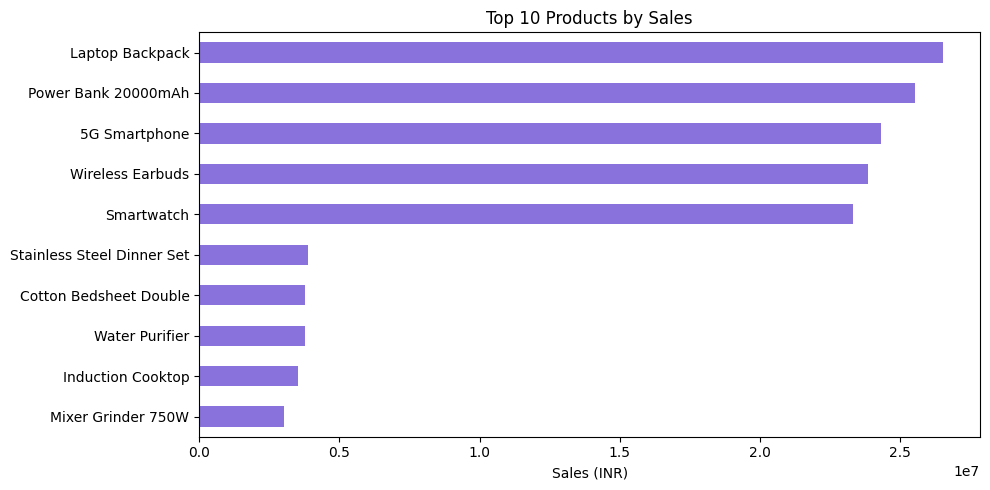

In [8]:
if "product" in df.columns and "sales" in df.columns:
    agg = {"sales": "sum"}
    if "profit" in df.columns: agg["profit"] = "sum"
    if "quantity" in df.columns: agg["quantity"] = "sum"
    top10 = df.groupby("product", dropna=False).agg(agg).sort_values("sales", ascending=False).head(10)
    display(top10)
    plt.figure(figsize=(10, 5))
    top10["sales"].sort_values().plot(kind="barh", color="#8a72dd")
    plt.title("Top 10 Products by Sales")
    plt.xlabel("Sales (INR)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("Product ranking unavailable: product and sales columns are required.")

## 8. Transaction distributions and outlier review

Distributions show skew and potential extreme values. IQR counts are diagnostic only; high-value orders are not automatically removed because they may be legitimate.

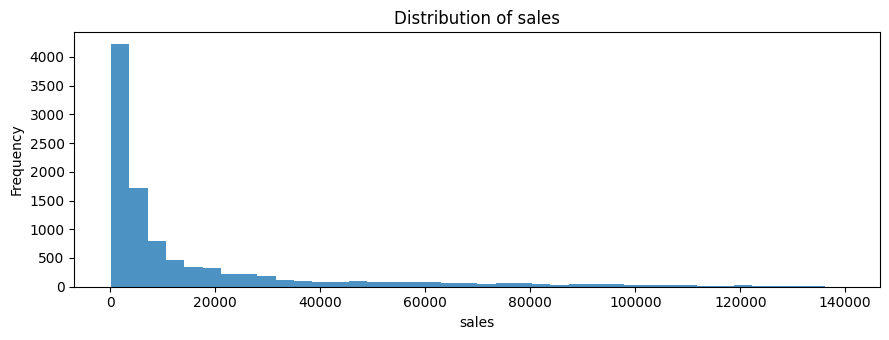

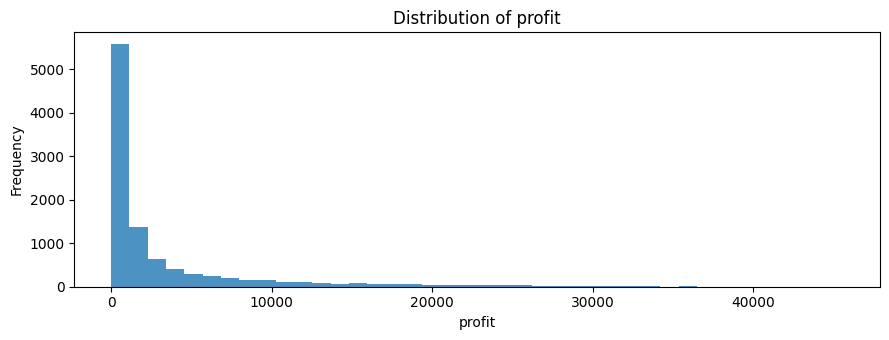

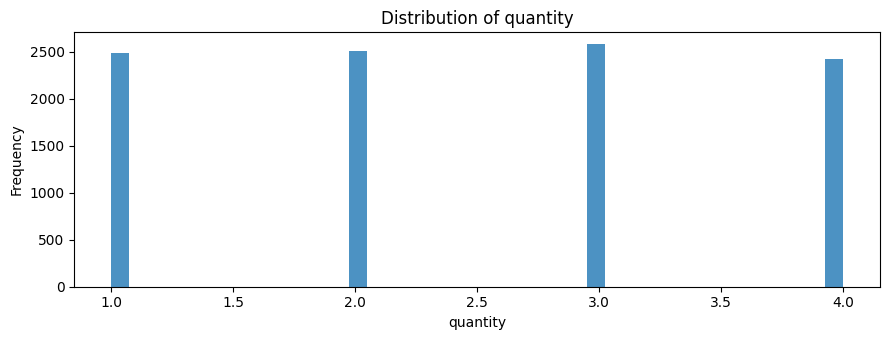

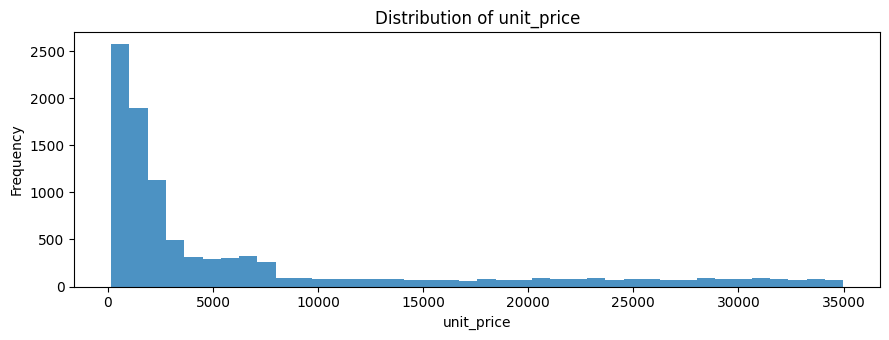

,column,iqr_outlier_count,outlier_pct,policy
0,sales,1250,12.50,Flag for review; not automatically removed
1,profit,1336,13.36,Flag for review; not automatically removed
2,quantity,0,0.00,Flag for review; not automatically removed
3,unit_price,1542,15.42,Flag for review; not automatically removed


In [9]:
for col in ["sales", "profit", "quantity", "unit_price"]:
    if col in df.columns and df[col].notna().any():
        fig, ax = plt.subplots(figsize=(9, 3.5))
        df[col].dropna().plot(kind="hist", bins=40, ax=ax, alpha=0.8)
        ax.set_title(f"Distribution of {col}")
        ax.set_xlabel(col)
        plt.tight_layout()
        plt.show()

outlier_rows = []
for col in ["sales", "profit", "quantity", "unit_price"]:
    if col in df.columns and df[col].notna().sum() >= 4:
        q1, q3 = df[col].quantile([.25, .75])
        iqr = q3 - q1
        if iqr > 0:
            mask = (df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)
            outlier_rows.append({"column": col, "iqr_outlier_count": int(mask.sum()),
                                 "outlier_pct": round(mask.mean()*100, 2),
                                 "policy": "Flag for review; not automatically removed"})
display(pd.DataFrame(outlier_rows))

## 9. Findings summary

The following summary is generated from the cleaned data currently loaded. It does not make claims about order status, payment methods, fulfilment, or geographic performance because those topics belong to the excluded PDF Tasks 3 and 4.

In [10]:
print("KEY FINDINGS")
print("-" * 60)
print(f"Rows available for analysis: {len(df):,}")
if kpis["total_sales"] is not None:
    print(f"Total sales: ₹{kpis['total_sales']:,.2f}")
if kpis["total_profit"] is not None:
    print(f"Total profit: ₹{kpis['total_profit']:,.2f}")
if kpis["total_orders"] is not None:
    print(f"Order count: {kpis['total_orders']:,}")
if kpis["average_order_value"] is not None:
    print(f"Average order value: ₹{kpis['average_order_value']:,.2f}")
if kpis["profit_margin_pct"] is not None:
    print(f"Profit margin: {kpis['profit_margin_pct']:.2f}%")
if "category" in df and "sales" in df:
    best = df.groupby("category")["sales"].sum().sort_values(ascending=False)
    if len(best):
        print(f"Highest-sales category: {best.index[0]} (₹{best.iloc[0]:,.2f})")
if "product" in df and "sales" in df:
    best_product = df.groupby("product")["sales"].sum().sort_values(ascending=False)
    if len(best_product):
        print(f"Top product by sales: {best_product.index[0]} (₹{best_product.iloc[0]:,.2f})")
print("\nData-quality decisions:")
print(f"- Exact duplicate rows removed: {cleaning_report['duplicate_rows_removed']}")
print(f"- Invalid rows removed: {cleaning_report['invalid_rows_removed']}")
print(f"- IQR outliers were flagged, not automatically deleted: {cleaning_report['outlier_counts_iqr']}")
print("- Numeric standardization was not applied to rupee values or quantities.")
print("- No model training or Tasks 3/4 analysis was performed.")

KEY FINDINGS
------------------------------------------------------------
Rows available for analysis: 10,000
Total sales: ₹155,789,893.89
Total profit: ₹33,167,008.49
Order count: 10,000
Average order value: ₹15,578.99
Profit margin: 21.29%
Highest-sales category: Electronics & Mobiles (₹123,569,507.07)
Top product by sales: Laptop Backpack (₹26,529,187.41)

Data-quality decisions:
- Exact duplicate rows removed: 0
- Invalid rows removed: 0
- IQR outliers were flagged, not automatically deleted: {'sales': 1250, 'profit': 1336, 'quantity': 0, 'unit_price': 1542}
- Numeric standardization was not applied to rupee values or quantities.
- No model training or Tasks 3/4 analysis was performed.
